# 02 - Polarity-Aware Otsu + Watershed & K-Means Segmentation

**Objective:**
1. Segment individual corn kernels from both **single-kernel closeups** and **dense touching multi-kernel piles**, on both **dark** and **light/white** backgrounds, using `CornDiseasePipeline.segment_kernels_otsu`.
2. Isolate mold/fungal lesions on individual kernels using mask-aware `CornDiseasePipeline.segment_fungus_kmeans`.
3. Verify the generated kernel crop dataset (`data/manifest_crop.csv`), ensuring **all 1,016 raw images** (`509` healthy, `507` contaminated) are represented.

In [1]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(".."))
from src.pipeline import CornDiseasePipeline

pipeline = CornDiseasePipeline(
    model_path="../models/svm_model_v1.joblib",
    scaler_path="../models/scaler.joblib",
    outlier_stats_path="../models/outlier_stats.joblib"
)

df_crop = pd.read_csv("../data/manifest_crop.csv")
print(f"Total Representative Kernel Crops in manifest_crop.csv: {len(df_crop)}")
print(f"Unique Raw Source Images Covered: {df_crop['file_asal'].nunique()} / 1016 (100.0%)")
print("\nUnique Raw Source Images per Class:")
print(df_crop.groupby("label")["file_asal"].nunique())
print("\nKernel Crops per Class:")
print(df_crop["label"].value_counts())
df_crop.head(10)

Total Representative Kernel Crops in manifest_crop.csv: 2759
Unique Raw Source Images Covered: 1016 / 1016 (100.0%)

Unique Raw Source Images per Class:
label
sehat             509
terkontaminasi    507
Name: file_asal, dtype: int64

Kernel Crops per Class:
label
terkontaminasi    1396
sehat             1363
Name: count, dtype: int64


,file_asal,file_crop,label,area_piksel
0,normal_001.JPG,normal_001_k1.png,sehat,1132
1,normal_001.JPG,normal_001_k2.png,sehat,628
2,normal_002.JPG,normal_002_k1.png,sehat,702
3,normal_002.JPG,normal_002_k2.png,sehat,660
4,normal_002.JPG,normal_002_k3.png,sehat,823
5,normal_003.JPG,normal_003_k1.png,sehat,994
6,normal_004.JPG,normal_004_k1.png,sehat,471
7,normal_004.JPG,normal_004_k2.png,sehat,396
8,normal_004.JPG,normal_004_k3.png,sehat,489
9,normal_005.JPG,normal_005_k1.png,sehat,679


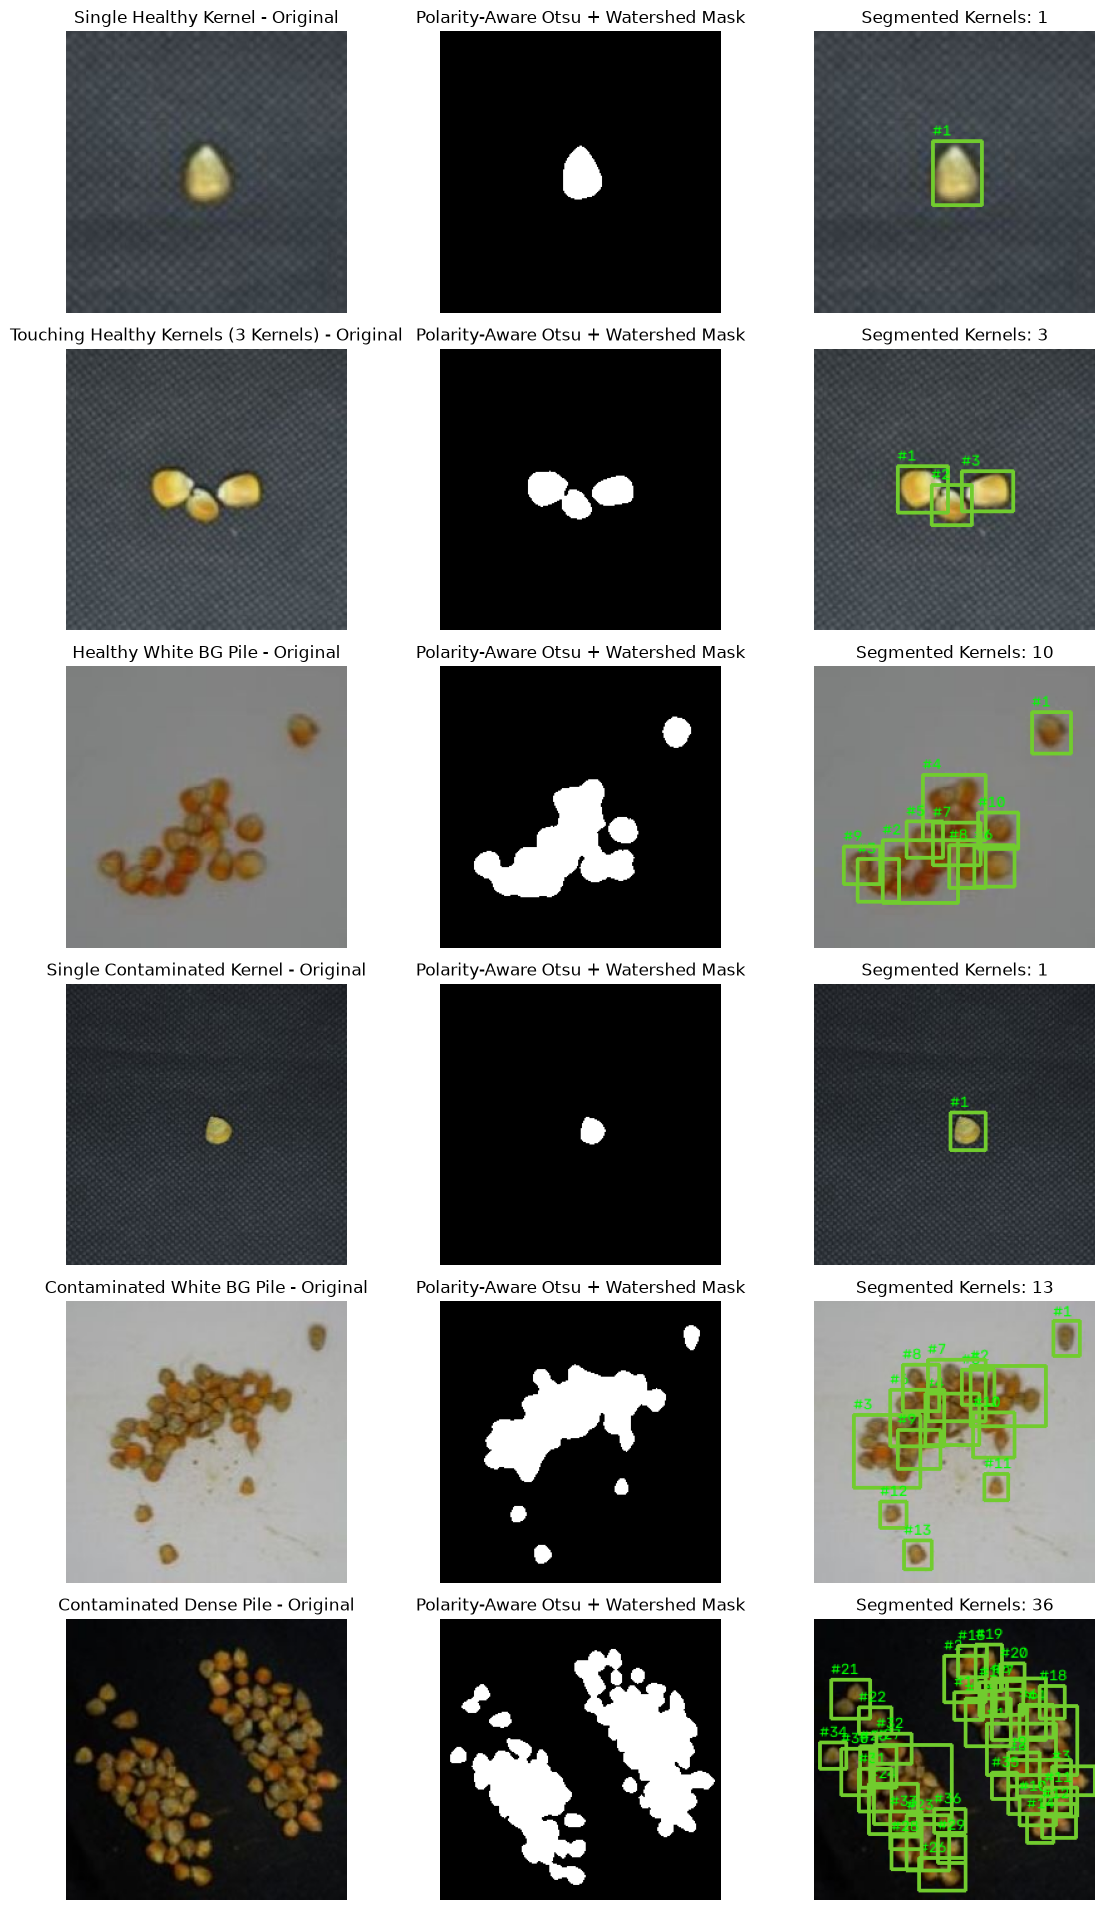

In [2]:
# Demonstrate segmentation on single-kernel, touching multi-kernel, dark BG, and white BG images
demo_cases = [
    ("../data/raw/sehat/normal_003.JPG", "Single Healthy Kernel"),
    ("../data/raw/sehat/normal_001.JPG", "Touching Healthy Kernels (3 Kernels)"),
    ("../data/raw/sehat/normal_151.JPG", "Healthy White BG Pile"),
    ("../data/raw/terkontaminasi/virus_001.JPG", "Single Contaminated Kernel"),
    ("../data/raw/terkontaminasi/virus_151.JPG", "Contaminated White BG Pile"),
    ("../data/raw/terkontaminasi/virus_301.JPG", "Contaminated Dense Pile")
]

fig, axes = plt.subplots(len(demo_cases), 3, figsize=(12, 3.2 * len(demo_cases)))
for row_idx, (fpath, title) in enumerate(demo_cases):
    img = cv2.imread(fpath)
    seg = pipeline.segment_kernels_otsu(img)
    vis = img.copy()
    for k in seg["kernels"]:
        x, y, w, h = k["bbox"]
        cv2.rectangle(vis, (x, y), (x + w, y + h), (46, 204, 113), 2)
        cv2.putText(vis, f"#{k['kernel_id']}", (x, max(y - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 255, 0), 1)

    axes[row_idx, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[row_idx, 0].set_title(f"{title} - Original")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(seg["otsu_mask"], cmap="gray")
    axes[row_idx, 1].set_title("Polarity-Aware Otsu + Watershed Mask")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    axes[row_idx, 2].set_title(f"Segmented Kernels: {len(seg['kernels'])}")
    axes[row_idx, 2].axis("off")

plt.tight_layout()
plt.show()

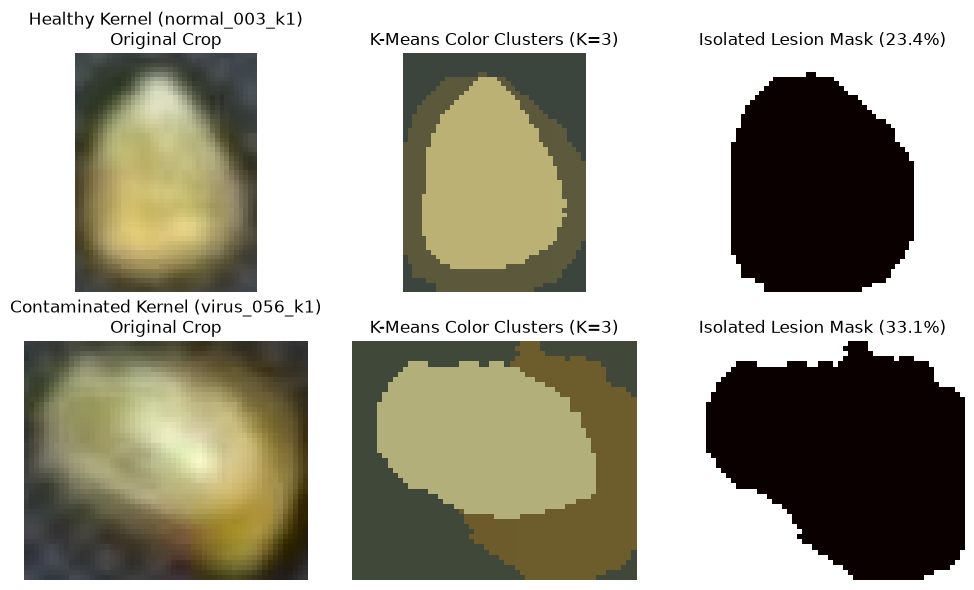

In [3]:
# Demonstrate Step 2B: K-Means Fungal Lesion Segmentation on Healthy vs Contaminated Kernel Crops
sample_sehat = cv2.imread("../data/cropped/sehat/normal_003_k1.png")
sample_kontam = cv2.imread("../data/cropped/terkontaminasi/virus_056_k1.png")

km_sehat = pipeline.segment_fungus_kmeans(sample_sehat, k=3)
km_kontam = pipeline.segment_fungus_kmeans(sample_kontam, k=3)

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for idx, (crop_img, km_res, name) in enumerate([
    (sample_sehat, km_sehat, "Healthy Kernel (normal_003_k1)"),
    (sample_kontam, km_kontam, "Contaminated Kernel (virus_056_k1)")
]):
    axes[idx, 0].imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
    axes[idx, 0].set_title(f"{name}\nOriginal Crop")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(cv2.cvtColor(km_res["clustered_bgr"], cv2.COLOR_BGR2RGB))
    axes[idx, 1].set_title("K-Means Color Clusters (K=3)")
    axes[idx, 1].axis("off")

    axes[idx, 2].imshow(km_res["mold_mask"], cmap="hot")
    axes[idx, 2].set_title(f"Isolated Lesion Mask ({km_res['mold_ratio']*100:.1f}%)")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()